<a href="https://colab.research.google.com/github/VAISHNAVI218CS/4NI25CS218_DAV_LAB/blob/main/4NI25CS218_EXP_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Accuracy: 0.804
Precision: 0.793
Recall: 0.667
F1 Score: 0.724
Confusion Matrix [[98 12]
 [23 46]]


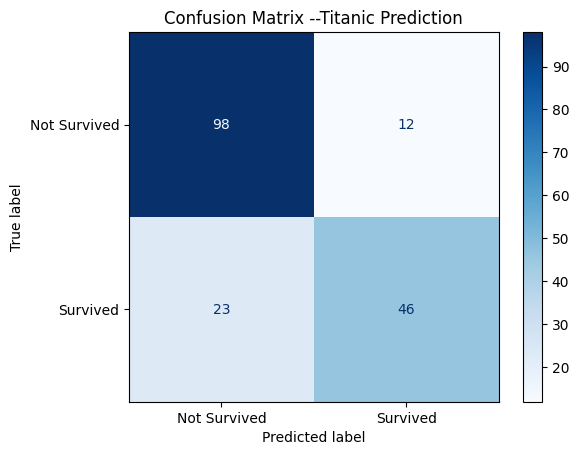

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
import matplotlib.pyplot as plt
df = pd.read_csv('/content/Titanic-Dataset (5).csv')
df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
y = df['Survived']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
clf = LogisticRegression(max_iter=1000)
clf.fit(X_tr, y_tr)
y_pred = clf.predict(X_te)
print("Accuracy:", round(accuracy_score(y_te, y_pred), 3))
print("Precision:", round(precision_score(y_te, y_pred), 3))
print("Recall:", round(recall_score(y_te, y_pred), 3))
print("F1 Score:", round(f1_score(y_te, y_pred), 3))
cm = confusion_matrix(y_te, y_pred)
print('Confusion Matrix', cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Survived', 'Survived']).plot(cmap='Blues')
plt.title('Confusion Matrix --Titanic Prediction')
plt.show()